
[DEBUG] Testando compatibilidade CWT/HDF5:
[INFO] Média BPM global: 72.27, Desvio padrão: 11.31
[TESTE] MSE: 129.5763, MAE: 9.8932, R²: -0.0132


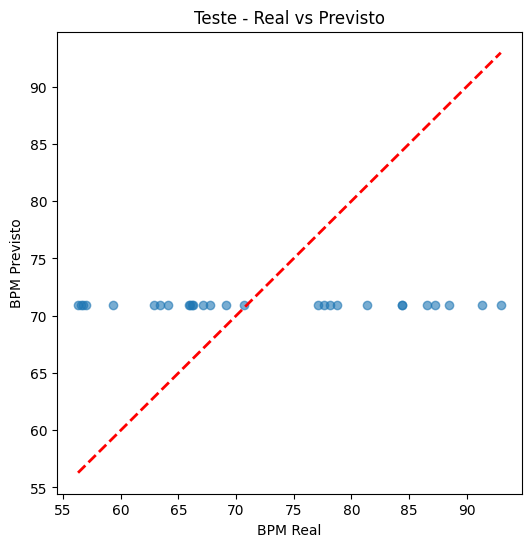

[INFO] Média BPM dataset: 72.27, std: 11.31
[INFO] Previsões reais: [70.97139709 70.97139709 70.97139709 70.97139709 70.97139709]
[INFO] Alvos reais: [77.08029187 78.18602532 78.76923075 81.38728327 56.73130162]


In [6]:
import torch
from torch.utils.data import DataLoader
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import matplotlib.pyplot as plt

# === Importa o Dataset e o Modelo ===
from IPPG_Dataset import IPPGDataset   # usa o que você me mostrou
from Model_CNN import IPPGCNN         # sua CNN

# Caminho da base de teste
test_root = r"C:\Users\Douglas\OneDrive - cefet-rj.br\Documentos\Material _ faculdade\Projeto IC\TESTE_COHFACE"

# Cria dataset e dataloader
test_dataset = IPPGDataset(root_dir=test_root)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

# Dispositivo
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Carrega modelo treinado
model = IPPGCNN().to(device)
model.load_state_dict(torch.load("model_cnn_ippg.pth", map_location=device))
model.eval()

# Avaliação
predictions = []
targets = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)

        predictions.extend(outputs.cpu().numpy())
        targets.extend(labels.cpu().numpy())

predictions = np.array(predictions).flatten()
targets = np.array(targets).flatten()

# === Como o target está normalizado, desnormalizando ===
mean_bpm = test_dataset.mean_bpm
std_bpm = test_dataset.std_bpm

predictions_real = mean_bpm + predictions * std_bpm
targets_real = mean_bpm + targets * std_bpm

# Métricas
mse = mean_squared_error(targets_real, predictions_real)
mae = mean_absolute_error(targets_real, predictions_real)
r2 = r2_score(targets_real, predictions_real)

print(f"[TESTE] MSE: {mse:.4f}, MAE: {mae:.4f}, R²: {r2:.4f}")

# === Gráfico Real vs Previsto ===
plt.figure(figsize=(6,6))
plt.scatter(targets_real, predictions_real, alpha=0.6)
plt.plot([targets_real.min(), targets_real.max()],
         [targets_real.min(), targets_real.max()],
         'r--', lw=2)
plt.xlabel("BPM Real")
plt.ylabel("BPM Previsto")
plt.title("Teste - Real vs Previsto")
plt.show()

print(f"[INFO] Média BPM dataset: {mean_bpm:.2f}, std: {std_bpm:.2f}")
print(f"[INFO] Previsões reais: {predictions_real[:5]}")
print(f"[INFO] Alvos reais: {targets_real[:5]}")


In [ ]:
import numpy as np 

file1 = r"c:\Users\Douglas\OneDrive - cefet-rj.br\Documentos\Material _ faculdade\Projeto IC\TREINAMENTO_COHFACE\1\0\data\data_cwt.npy"
file2 = r"c:\Users\Douglas\OneDrive - cefet-rj.br\Documentos\Material _ faculdade\Projeto IC\TREINAMENTO_COHFACE\10\0\data\data_cwt.npy"

data1 = np.load(file1)
data2 = np.load(file2)

print("Shape do arquivo 1:", data1.shape)
print("Shape do arquivo 2:", data2.shape)
print("São exatamente iguais:", np.array_equal(data1, data2))

diff = np.abs(data1 - data2)
print("Diferença média:", np.mean(diff))
print("Diferença máxima:", np.max(diff))
print(data1[1])
print(data2[1])
if not np.array_equal(data1, data2):
    indices_diff = np.argwhere(diff != 0)
    print(f"Número de diferenças: {len(indices_diff)}")
    print("Primeiras diferenças:", indices_diff[:10])

Shape do arquivo 1: (74, 261)
Shape do arquivo 2: (74, 261)
São exatamente iguais: False
Diferença média: 0.09162145911506696
Diferença máxima: 0.6530849250029509
[0.210131   0.06308013 0.04200609 0.03989551 0.04289445 0.04564429
 0.03970864 0.02358639 0.01426256 0.02701624 0.03259349 0.02878455
 0.02573365 0.03175108 0.04130763 0.04378489 0.03502809 0.01978549
 0.00839178 0.01465777 0.02349136 0.02831122 0.02822882 0.0245807
 0.01940176 0.01430738 0.01024454 0.00641674 0.00850112 0.02217475
 0.03470923 0.03609888 0.02508116 0.01045971 0.00247454 0.00145829
 0.00231923 0.00996433 0.02179757 0.03054202 0.02858564 0.01632554
 0.00494441 0.00364989 0.00868285 0.01270818 0.00785147 0.00999008
 0.00969973 0.02077622 0.03588546 0.02989854 0.02707359 0.05919981
 0.07556976 0.06171286 0.03117478 0.00905822 0.02602817 0.05131707
 0.05363407 0.03505823 0.07725781 0.12488377 0.1314275  0.09817264
 0.04992126 0.01829445 0.02586587 0.03238016 0.03403442 0.0356377
 0.03661525 0.03333111 0.02385937 0